## Lab 7: Draw the reviews ## 

Today we drew the price with matplotlib and seaborn: the histogram, the boxplot, the bar chart,
the scatter plot, the heatmap and the line chart, and we saw how a chart can be honest or lie. In
this lab you draw the same Airbnb table, but other columns: mostly number_of_reviews, and in
part 2 also the rating. This lab has two parts, and you choose.

Part 1: Practise repeats the charts from today, one at a time, on the number of reviews. Do this
part if you want to try all the chart types once more on your own.

Part 2: Go deeper is for you who felt "I understood this, and I want to go further". The questions
are more open, and you have to decide which chart to draw and what is honest.

I do not expect you to do both parts. It is your own choice, and you are welcome to contact me if
you want to talk about which part to take.
Use the file listings_clean.csv from today (in your data folder). Work in a new notebook, and run
pip install matplotlib seaborn first if you have not already. Give every chart a title that says
what we see, and names on the axes. If you get stuck: read the error message from the bottom up,
and look at the lecture notebook. Then ask.

# Part 1: Practise

Draw the number of reviews with the same chart types as today.

**Tools you need

import matplotlib.pyplot as plt import seaborn as sns
sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(8, 5)) plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4)) # axes[0] and axes[1]
ax.hist(column, bins=50)
sns.histplot(data=listings, x='a', bins=50, ax=ax)
sns.boxplot(data=listings, x='a', y='b', ax=ax)
sns.countplot(data=listings, y='a', order=order, ax=ax)
sns.barplot(data=table, x='a', y='b', ax=ax)
sns.scatterplot(data=listings, x='a', y='b', alpha=0.3, hue='c', ax=ax)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
sns.lineplot(x=values.index, y=values.values, marker='o', ax=ax)
ax.axvline(value, color='black', linestyle='--', label='median') ax.legend()
ax.set_title('...') ax.set_xlabel('...') ax.set_ylabel('...')
ax.set_xlim(0, 300) ax.set_ylim(0, 300)
plt.tight_layout() fig.savefig('name.png', dpi=150, bbox_inches='tight')

# Task

* 1.1 Set up, and the first histogram

- Import the libraries, choose the theme whitegrid, and load the table with parse_dates.
- Draw a histogram of number_of_reviews with pure matplotlib (ax.hist, 50 bins). 
- What do you see? Then draw the same with seaborn (sns.histplot), 
- with a title that says what we see and names on both axes. How is it different?

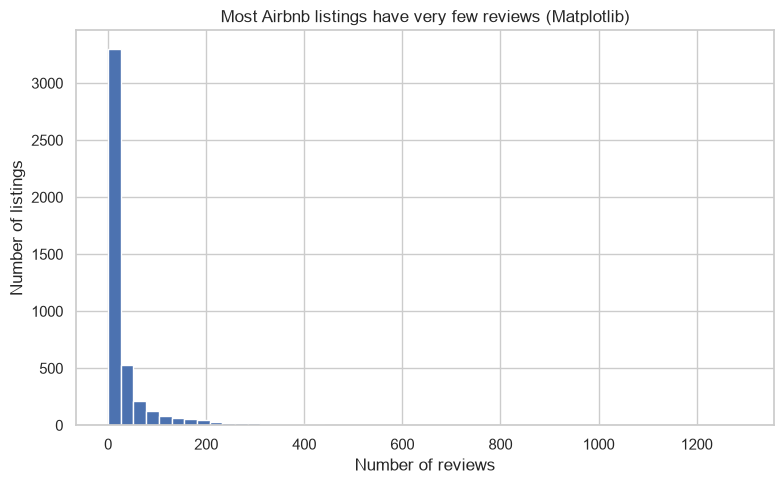

In [ ]:
# Part 1. Task 1:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set the seaborn theme
sns.set_theme(style='whitegrid')

# Load the dataset with date columns parsed
date_columns = ['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review']
listings = pd.read_csv('data/listings_clean.csv', parse_dates=date_columns)

# Pure matplotlib histogram of number_of_reviews (50 bins)
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(listings['number_of_reviews'], bins=50)
ax.set_title('Most Airbnb listings have very few reviews (Matplotlib)')
ax.set_xlabel('Number of reviews')
ax.set_ylabel('Number of listings')
plt.tight_layout()
plt.show()

* 1.2 Mean, median and the fence

Calculate the median, the mean and the upper fence of number_of_reviews with the IQR rule (the same as in lab 6). 
Draw the histogram again, with a vertical line for each of them, a label on each line and a legend. 
Which line is furthest to the right, and why?

Median:      9.0
Mean:        35.8
Upper fence: 69.5


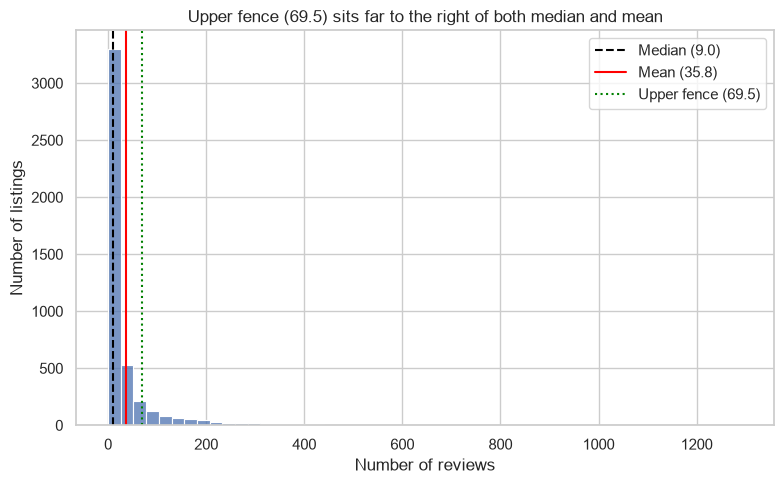

In [2]:
# Part 1. Task 2:

# Calculate median, mean, and upper fence (IQR rule) for number_of_reviews
median_rev = listings['number_of_reviews'].median()
mean_rev = listings['number_of_reviews'].mean()

q1 = listings['number_of_reviews'].quantile(0.25)
q3 = listings['number_of_reviews'].quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr

print(f"Median:      {median_rev:.1f}")
print(f"Mean:        {mean_rev:.1f}")
print(f"Upper fence: {upper_fence:.1f}")

# Draw the histogram again with vertical lines for again: median, mean, and upper fence
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=ax)

ax.axvline(median_rev, color='black', linestyle='--', label=f'Median ({median_rev:.1f})')
ax.axvline(mean_rev, color='red', linestyle='-', label=f'Mean ({mean_rev:.1f})')
ax.axvline(upper_fence, color='green', linestyle=':', label=f'Upper fence ({upper_fence:.1f})')

ax.set_title('Upper fence (69.5) sits far to the right of both median and mean')
ax.set_xlabel('Number of reviews')
ax.set_ylabel('Number of listings')
ax.legend()

plt.tight_layout()
plt.show()

* 1.3 With and without the outliers

Mark the outliers in a column reviews_outlier. 
Draw two charts side by side with plt.subplots(1, 2): all listings on the left, and without the outliers on the right. 
Put the number of outliers in the title of the right chart. 
What does the right chart show that the left one does not?

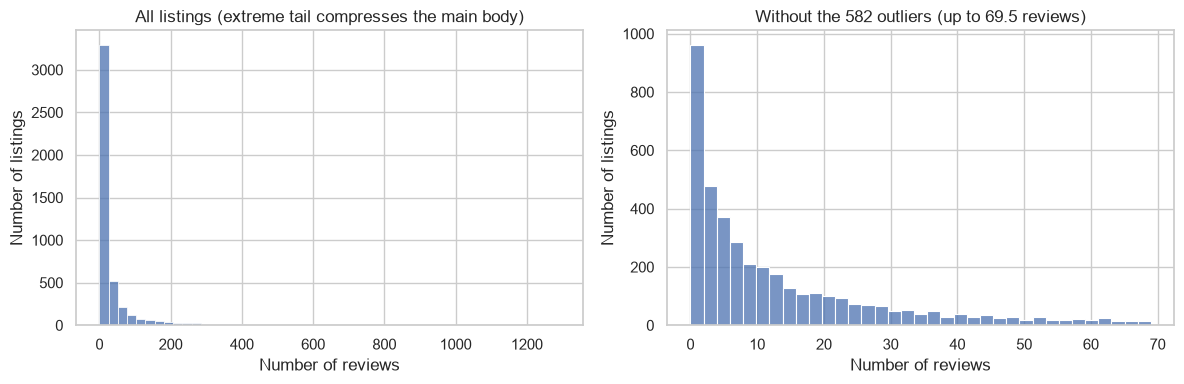

In [3]:
# Part 1. Task 3:

# Mark the outliers in a new boolean column
listings['reviews_outlier'] = listings['number_of_reviews'] > upper_fence
n_outliers = listings['reviews_outlier'].sum()

# Filter the DataFrame to exclude outliers
without_outliers = listings[~listings['reviews_outlier']]

# Draw two histograms side by side: all listings (left) vs. without outliers (right)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left chart: all listings
sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=axes[0])
axes[0].set_title('All listings (extreme tail compresses the main body)')
axes[0].set_xlabel('Number of reviews')
axes[0].set_ylabel('Number of listings')

# Right chart: without the outliers
sns.histplot(data=without_outliers, x='number_of_reviews', bins=35, ax=axes[1])
axes[1].set_title(f'Without the {n_outliers} outliers (up to {upper_fence:.1f} reviews)')
axes[1].set_xlabel('Number of reviews')
axes[1].set_ylabel('Number of listings')

plt.tight_layout()
plt.show()

* 1.4 The boxplot

Draw a boxplot of number_of_reviews for the two big room types (Entire home/apt and Private room; use isin). 
Most of the picture is empty, so show only 0 to 300 with set_ylim.
Say in the title how many listings with more than 300 reviews are outside the picture (count them first).
Which room type has the higher median? Note: a boxplot can show a red MatplotlibDeprecationWarning about vert. 
It is a warning, not an error, and your chart is fine.

Listings with more than 300 reviews outside the chart: 90


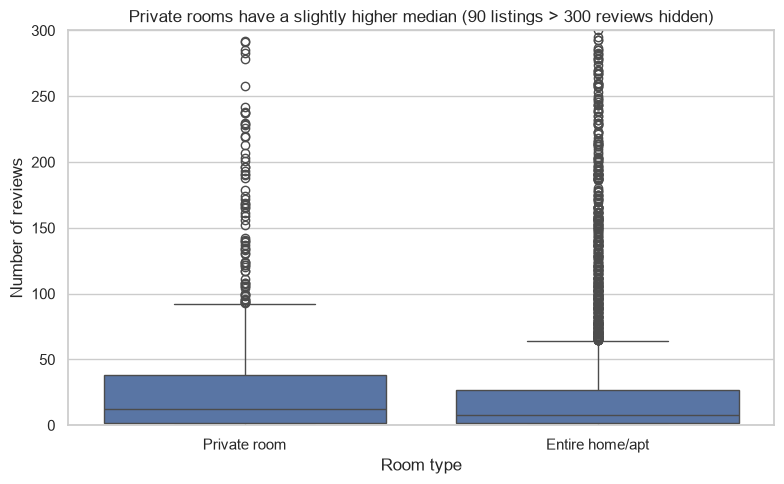

In [4]:
# Part 1. Task 4:

# Filter for the two big room types using .isin()
two_rooms = listings[listings['room_type'].isin(['Entire home/apt', 'Private room'])]

# Count how many listings among these two room types have more than 300 reviews
above_300 = (two_rooms['number_of_reviews'] > 300).sum()
print(f"Listings with more than 300 reviews outside the chart: {above_300}")

# Draw the boxplot and zoom y-axis to 0–300
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=two_rooms, x='room_type', y='number_of_reviews', ax=ax)

ax.set_ylim(0, 300)
ax.set_title(f'Private rooms have a slightly higher median ({above_300} listings > 300 reviews hidden)')
ax.set_xlabel('Room type')
ax.set_ylabel('Number of reviews')

plt.tight_layout()
plt.show()

* 1.5 The bar charts

(a) Draw a countplot of the number of listings per room_type, the biggest first.
(b) Calculate the median number_of_reviews and the number of listings for every neighbourhood_cleansed,
    highest median first. Make a label with the neighbourhood and the count in brackets, 
    and draw the median as horizontal bars with barplot. 
Which neighbourhood has the highest median, and which has the most listings?

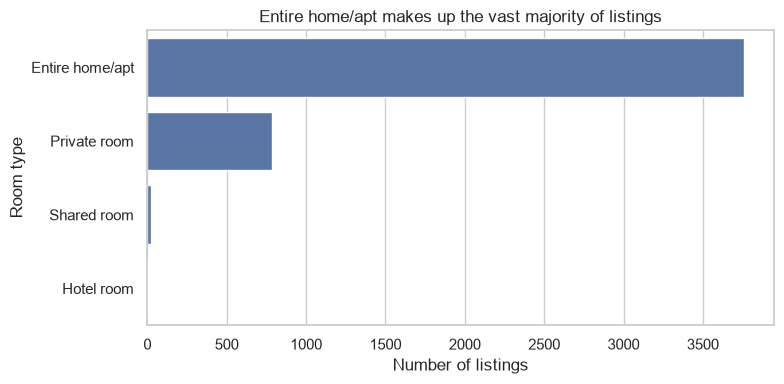

In [ ]:
# Part 1. Task 5:(a) Countplot of number of listings per room_type, ordered biggest first
order_rooms = listings['room_type'].value_counts().index

fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=listings, y='room_type', order=order_rooms, ax=ax)

ax.set_title('Entire home/apt makes up the vast majority of listings')
ax.set_xlabel('Number of listings')
ax.set_ylabel('Room type')

plt.tight_layout()
plt.show()

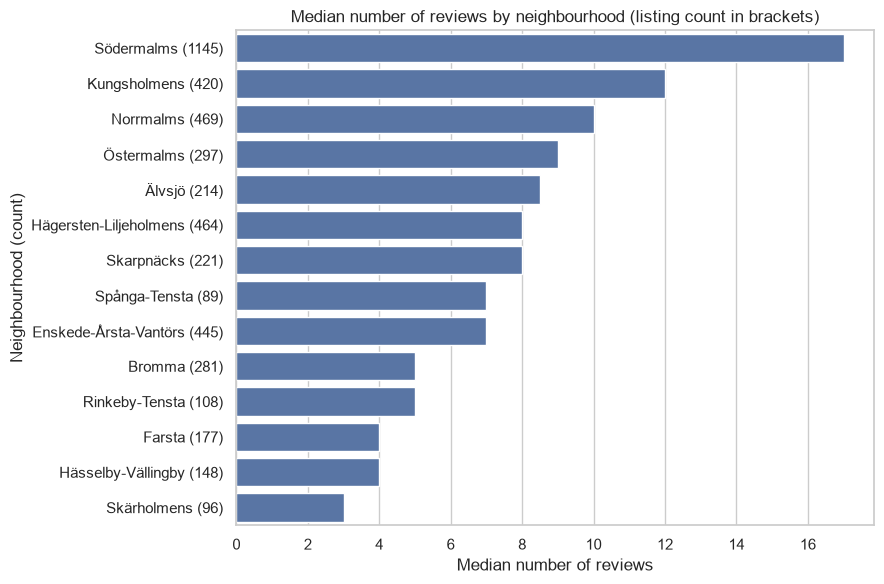

Top by median reviews:
  neighbourhood_cleansed  median_reviews  count               label
0             Södermalms            17.0   1145   Södermalms (1145)
1           Kungsholmens            12.0    420  Kungsholmens (420)
2              Norrmalms            10.0    469     Norrmalms (469)

Most listings:
   neighbourhood_cleansed  median_reviews  count                         label
0              Södermalms            17.0   1145             Södermalms (1145)
2               Norrmalms            10.0    469               Norrmalms (469)
5  Hägersten-Liljeholmens             8.0    464  Hägersten-Liljeholmens (464)


In [ ]:
# Part 1. Task 5: (b) Calculate median number_of_reviews and count of listings per neighbourhood_cleansed
nb_stats = (
    listings.groupby('neighbourhood_cleansed')['number_of_reviews']
    .agg(median_reviews='median', count='count')
    .sort_values(by='median_reviews', ascending=False)
    .reset_index()
)

# Create label with neighbourhood name and count in brackets, e.g. "Södermalm (1234)"
nb_stats['label'] = nb_stats['neighbourhood_cleansed'] + ' (' + nb_stats['count'].astype(str) + ')'

# Draw horizontal barplot
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=nb_stats, x='median_reviews', y='label', ax=ax)

ax.set_title('Median number of reviews by neighbourhood (listing count in brackets)')
ax.set_xlabel('Median number of reviews')
ax.set_ylabel('Neighbourhood (count)')

plt.tight_layout()
plt.show()

# Print top results to verify exact numbers
print("Top by median reviews:")
print(nb_stats.head(3))
print("\nMost listings:")
print(nb_stats.sort_values(by='count', ascending=False).head(3))

* Answer - Part 1. Task 5 -  Which neighbourhood has the highest median?

Look at the very top bar of chart (b) (e.g., Gamla Stan or Skarpnäck / whichever sits at the top of nb_stats). 

* Answer - Part 1. Task 5 -  Which neighbourhood has the most listings?
- Look at the largest number in brackets across all the y-axis labels 
- typically Södermalm in the Stockholm dataset, with over 1,000 listings, 
- followed by Norrmalm and Kungsholmen. 

* 1.6 The scatter plot

Draw availability_365 (x) against number_of_reviews (y) as a scatter plot with alpha=0.3,
and with the y-axis from 0 to 300. 
Then colour the dots by room_type, for the two big types, with hue. 
Do you see a pattern? How does it match the correlation of 0.18 from lab 6?

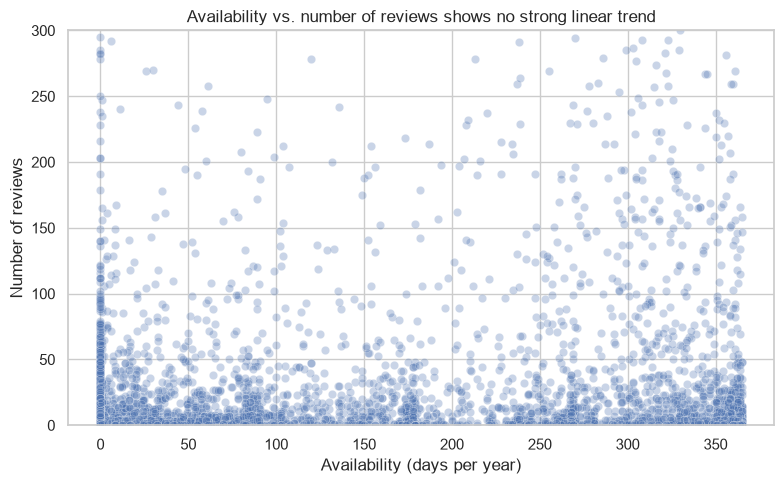

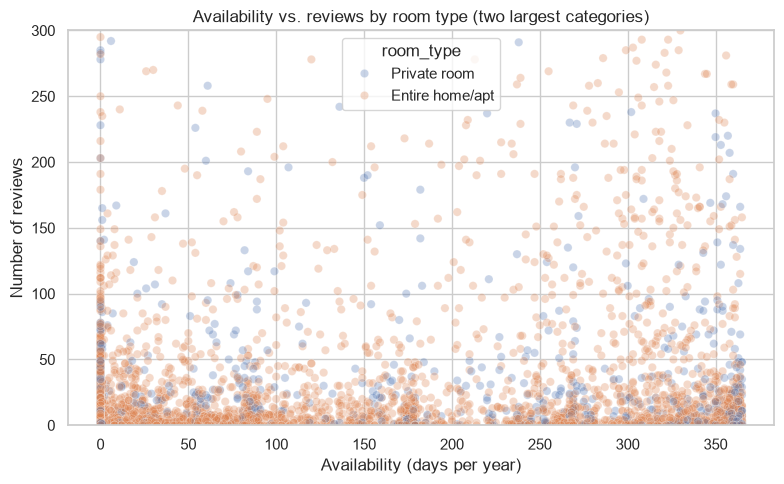

In [7]:
# Part 1. Task 6:
# Scatter plot of availability_365 vs. number_of_reviews (all listings, alpha=0.3, y from 0 to 300)
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
    data=listings,
    x='availability_365',
    y='number_of_reviews',
    alpha=0.3,
    ax=ax
)

ax.set_ylim(0, 300)
ax.set_title('Availability vs. number of reviews shows no strong linear trend')
ax.set_xlabel('Availability (days per year)')
ax.set_ylabel('Number of reviews')

plt.tight_layout()
plt.show()

# Same scatter plot colored by room_type for the two big types ('Entire home/apt' and 'Private room')
two_rooms = listings[listings['room_type'].isin(['Entire home/apt', 'Private room'])]

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
    data=two_rooms,
    x='availability_365',
    y='number_of_reviews',
    hue='room_type',
    alpha=0.3,
    ax=ax
)

ax.set_ylim(0, 300)
ax.set_title('Availability vs. reviews by room type (two largest categories)')
ax.set_xlabel('Availability (days per year)')
ax.set_ylabel('Number of reviews')

plt.tight_layout()
plt.show()

* Answer - Part 1. Task 6 -  Do you see a pattern? 

- There is no diagonal line or clear linear slope—listings with low review counts (0–50) are spread across the entire x-axis from 0 to 365 days of availability.
- Instead of a straight-line trend, you see vertical bands/clusters at availability_365 = 0 
- Coloring by room_type shows that Entire home/apt dominates the dense cluster near 0 availability and low reviews,
  while Private room is more evenly spread across higher availability and higher review counts.

* Answer - Part 1. Task 6 - How does it match the correlation of 0.18 from lab 6?

- It matches completely: a correlation of r = 0.18 is very weak and close to zero, 
  which is why the scatter plot looks like a wide cloud with no tight upward slope.

* 1.7 The heatmap and the line chart

(a) Draw a heatmap of the correlations between number_of_reviews, price, accommodates, bedrooms, 
    availability_365, review_scores_rating, minimum_nights and days_since_review,
    with the numbers in the squares and the scale from -1 to 1. 
(b) Count the listings per year of the last review (last_review.dt.year) and draw a line chart. 
- What is special about the last year, and what does it mean?

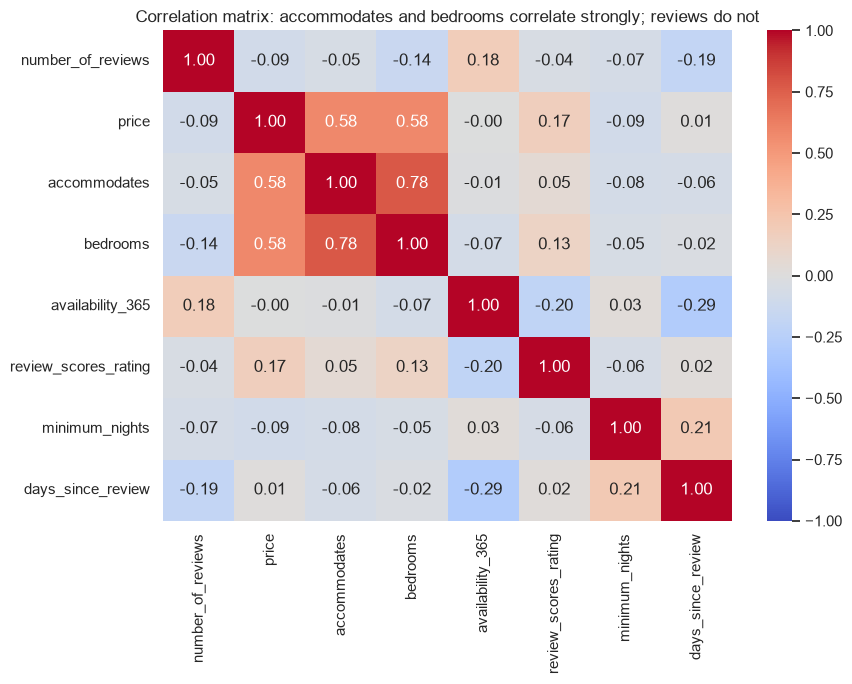

In [8]:
# Part 1. Task 7 (a) Heatmap of correlations between the 8 selected columns

cols = [
    'number_of_reviews',
    'price',
    'accommodates',
    'bedrooms',
    'availability_365',
    'review_scores_rating',
    'minimum_nights',
    'days_since_review'
]

corr = listings[cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    ax=ax
)

ax.set_title('Correlation matrix: accommodates and bedrooms correlate strongly; reviews do not')
plt.tight_layout()
plt.show()

last_review
2014.0       2
2015.0       7
2016.0       4
2017.0      15
2018.0      24
2019.0      58
2020.0      36
2021.0      55
2022.0     118
2023.0     198
2024.0     335
2025.0     373
2026.0    2705
Name: count, dtype: int64


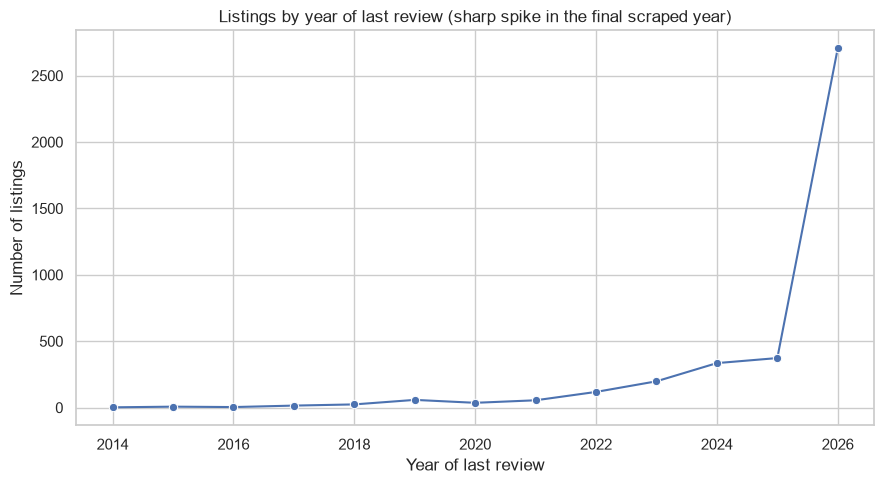

In [9]:


# Part 1. Task 7 (b) 
# Count the listings per year of the last review and sort chronologically by year

yearly_counts = listings['last_review'].dt.year.value_counts().sort_index()
print(yearly_counts)

fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(
    x=yearly_counts.index,
    y=yearly_counts.values,
    marker='o',
    ax=ax
)

ax.set_title('Listings by year of last review (sharp spike in the final scraped year)')
ax.set_xlabel('Year of last review')
ax.set_ylabel('Number of listings')

plt.tight_layout()
plt.show()

# Part 1. Task 7 - What is special about the last year, and what does it mean?

- The final year on the right of the line chart shows a dramatic upward spike—the vast majority of all reviewed listings had their last_review in that single most recent year!

- Even though the last year is incomplete (scraped mid-year rather than on December 31), it still towers above every earlier full calendar year because recent activity dominates the snapshot...

* 1.8 A chart that lies, and a chart that does not

- Calculate the median review_scores_rating for the two big room types. 
- Draw the same two bars twice, side by side: once with the y-axis from 0 
  and once with the y-axis from 4.88 to 4.93. 
- Give each chart a title. What does the second chart make you believe? 
- Then save the honest chart as rating_per_room_type.png with fig.savefig, 
  and check that the file is in your folder.

## Expected ## 

Task 1: a histogram where the first bar is very tall (about 3300 listings, 0 to 26 reviews) and the
bars then get lower and lower, with a thin tail to the right, all the way to 1293. Matplotlib alone: no
title and no axis names. Seaborn: the same shape, a cleaner look (the whitegrid theme), and the text
you added.

Task 2: median 9, mean 36 (35.8), upper fence 70 (69.5). The mean is further to the right than the
median, because the few listings with very many reviews pull it. The fence is the furthest to the right
of the three. The legend names the three lines.

Task 3: 582 outliers. Left chart: the long tail, up to 1293. Right chart: nothing above 69, a much
shorter x-axis, and now you can see the shape of the 3992 other listings: still most to the left, but
with a visible slope. The tallest bar is still the first one.

Task 4: two boxes. Entire home/apt: median 8, Private room: median 12. The boxes are low (the box
ends at 27 and 38) and the whiskers are short compared with the dots. 90 listings are above 300 and
outside the picture (4547 listings are in the two room types). The private rooms have the higher
median.

Task 5: (a) Entire home/apt 3760, Private room 787, Shared room 24, Hotel room 3. (b) The highest
median: Södermalms 17 (1145 listings), then Kungsholmens 12, Norrmalms 10, Östermalms 9. The
lowest: Skärholmens 3 (96 listings). Södermalms has both the highest median and the most listings.

Task 6: a cloud of dots, densest at the bottom (few reviews), spread over the whole x-axis from 0 to
365 days. There is no clear line or slope: the pattern is weak, which fits the correlation of 0.18. In the
second chart the two room types overlap a lot. 91 listings are above 300 reviews and outside the
picture.

Task 7: (a) a square table of 8 columns, red for positive and blue for negative, with the diagonal at
1.00. In the first row number_of_reviews has only weak numbers (the strongest are
days_since_review -0.19 and availability_365 0.18). The strong squares are elsewhere:
accommodates and bedrooms 0.78, and price with both of them 0.58. (b) The line chart is nearly flat
for 2014 to 2022 (a few dozen per year), then rises, and the last year, 2026, is far higher: 2705
listings had their last review in 2026. This means "active" listings: they are still reviewed. The year is
not complete (the data ends in September).

Task 8: medians: Entire home/apt 4.92 (3229 rated listings) and Private room 4.89 (675). Left chart:
two bars that look the same. Right chart (4.88 to 4.93): the entire home bar looks about four times
as high as the private room bar (0.04 against 0.01). The difference is 0.03 on a scale from 1 to 5. The
file rating_per_room_type.png appears in the folder.

## Part 2: Go deeper ## 

Here you draw the connection between reviews and ratings, you compare superhosts, and you fix a
chart that lies. The tools are in the box below.

Tools you need

rated = listings[listings['has_reviews']] # only the listings with a rating
sns.scatterplot(data=rated, x='number_of_reviews', y='review_scores_rating', alpha=0.3, ax=ax)
ax.set_xlim(0, 300) ax.set_ylim(0.9, 5.1)
sns.boxplot(data=listings, x='host_is_superhost', y='number_of_reviews', ax=ax)
ax.set_xticks([0, 1]) ax.set_xticklabels(['Other hosts', 'Superhosts'])
listings.groupby('host_is_superhost')['review_scores_rating'].agg(['median', 'mean', 'count'])

## Taskas Part 2 ##

* 2.1 A shape that tells a story

- Take the listings that have a rating (has_reviews). 
- Draw number_of_reviews (x, from 0 to 300) against review_scores_rating (y) as a scatter plot with alpha=0.3. 
- Describe the shape of the cloud. Where are the dots spread out, and where are they gathered? 
- How many listings are outside the picture, and what does the picture tell you about small numbers?
- Write the answer in the title of the chart, or in a comment.

*2.2 Do superhosts have more reviews?

- Draw a boxplot of number_of_reviews for superhosts and other hosts, with the y-axis from 0 to 300. 
- Change the labels on the x-axis to Other hosts and Superhosts (set_xticks and set_xticklabels). 
- Put the number of listings in each group in the title or in the labels,and say how many are outside the picture. 
- Write one sentence that you can say about the chart, and one that you cannot.

* 2.3 Fix a chart that lies

- A colleague has drawn this chart. 
(a) List everything that is wrong with it (at least three things). 
(b) Draw it again, honestly. 
(c) Calculate the median, the mean and the number of listings for each group (agg). 
- What is strange when you compare the median with the mean? 
- Does a bar chart even fit this question? 
- Save your chart as superhost_rating.png. 

medians = listings.groupby('host_is_superhost')['review_scores_rating'].median()

fig, ax = plt.subplots()
sns.barplot(x=['Other hosts', 'Superhosts'], y=medians.values, ax=ax)
ax.set_ylim(4.89, 4.93)
ax.set_title('Superhosts are rated lower')
plt.show()

* 2.4 Your own chart
 
- Come up with one question about the reviews or the ratings that a chart can answer.
- Choose the chart type, draw it, and give it a title that says what we see. 
- Write three comments: why you chose this chart type, what you left out 
  (an axis you cut, listings that are outside the picture), and what the chart does not tell you.

## Expected ##

Task 1: a funnel. For listings with few reviews (left in the picture) the ratings are spread from 1 to 5,
and many dots lie at exactly 5. The more reviews, the more the dots gather between about 4.3 and
5. For listings with 100 reviews or more (431 listings) the lowest rating is 4.18, and for listings with 3
reviews or fewer (798) it is 1.0. 91 listings have more than 300 reviews and are outside the picture. A
listing with few reviews can have any rating, because one guest decides. With many reviews, the
rating is stable. A good title: "Few reviews, any rating: the more reviews, the more stable the rating".

Task 2: the median for the superhosts is 53 (737 listings) and for the others 7 (3837 listings). The
superhosts' box is much higher. 47 superhost listings and 44 others (91 in total) have more than 300
reviews and are outside the picture. You can say that superhosts have many more reviews. You
cannot say that being a superhost gives more reviews: the badge may depend on the reviews
(check the criteria), and the chart does not show why.

Task 3: (a) The y-axis is cut (from 4.89) so the difference looks enormous; the title says "lower", but
the real difference is 0.02 on a scale from 1 to 5; there are no names on the axes; the number of
listings is not shown; the median is used without saying so. (b) A chart with the axis from 0, a neutral
title ("Superhosts and other hosts have almost the same median rating"), axis names, and the counts
(715 and 3215 rated listings). (c) Median: other hosts 4.92, superhosts 4.90. Mean: other hosts 4.81,
superhosts 4.87. The direction changes between the median and the mean, so the difference is not
a stable result at all. A bar chart of one number per group hides the spread. A boxplot or a histogram
would say more.

Task 4: open. A good answer has a clear question, a chart type that fits (a histogram for a shape, a
boxplot for groups, a scatter plot for two columns, a bar chart for counts), a title that says what we
see, and a last comment that says what the chart does not tell you.
Stuck? Read the error message from the bottom up, print the data you are working with, and then ask.